
# MODULE 35.7 — PITCH, PROSODY AND VOICE-RELATED FEATURES

**Very important for Speech Emotion Recognition (SER)**

So far, we've extracted:

- Time-domain features (RMS, ZCR).
- Spectral features (centroid, bandwidth, rolloff, etc.).
- Log-Mel representations.
- MFCC, Delta and Delta-Delta coefficients.

Now we're moving into how a human voice is produced and how its delivery changes with emotion.

Here's an important distinction:

- **MFCCs** describe spectral characteristics.
- **Prosodic features** describe characteristics such as pitch, loudness, speaking rate, rhythm and pauses.

For SER, these two groups can complement each other.

---

## 1. Fundamental frequency (F0) and perceived pitch

**Must Know**

First, understand the difference between frequency and pitch.

**Fundamental frequency (F0)** is the frequency of the fundamental component of a periodic or approximately periodic voiced signal.

**Pitch** is the perceptual sensation of how high or low a sound appears to us.

They are closely related, but they are not exactly the same thing.

For example:

- A person speaking with a low voice generally has a lower F0.
- A person speaking with a high voice generally has a higher F0.

### Mathematical relationship

If the fundamental period is $T_0$, then:

$$
F_0=\frac{1}{T_0}
$$

Where:

- $F_0$ = fundamental frequency in Hz.
- $T_0$ = duration of one fundamental period in seconds.

Example:

If the vocal waveform repeats every 0.01 seconds:

$$
F_0=\frac{1}{0.01}=100\text{ Hz}
$$

If it repeats every 0.005 seconds:

$$
F_0=\frac{1}{0.005}=200\text{ Hz}
$$

Therefore, a shorter fundamental period corresponds to a higher fundamental frequency.

### Why is F0 useful for SER?

Emotional expression can influence vocal pitch.

| Emotion / delivery | Possible pitch characteristics |
|---|---|
| Excitement | Higher pitch or wider pitch variation |
| Anger | Higher or more variable pitch in some speakers |
| Sadness | Lower pitch or reduced variation in some speakers |
| Neutral | More moderate or consistent pitch patterns |

These are tendencies, not universal rules. Individual speakers and speaking styles can produce very different patterns.

**SER takeaway:** We should study not just the average F0, but also how F0 changes throughout the utterance.

---

## 2. Pitch tracking

**Must Know**

Pitch tracking means estimating the fundamental frequency at successive time frames.

Imagine a four-second recording.

Instead of calculating one F0 value for the complete recording, we estimate F0 repeatedly.

Example:

| Time | Estimated F0 |
|---|---:|
| 0.0 s | 120 Hz |
| 0.1 s | 125 Hz |
| 0.2 s | 140 Hz |
| 0.3 s | 155 Hz |
| 0.4 s | 145 Hz |
| 0.5 s | 130 Hz |

These values form a **pitch contour**.

### How is F0 estimated?

Pitch trackers use properties of voiced speech to estimate periodicity.

Common approaches include:

- Autocorrelation-based methods.
- YIN.
- pYIN.
- Harmonic-based methods.

For our project, we'll initially use `librosa.pyin()`.

### What is pYIN?

pYIN is a probabilistic extension of the YIN pitch-estimation approach.

It estimates possible fundamental frequencies and uses probabilistic temporal decoding to produce a more consistent pitch track.

It also provides voiced/unvoiced decisions and voiced probabilities.

**Important:** A pitch tracker estimates F0; it does not guarantee that every estimate is correct.

---

## 3. Voiced and unvoiced frames

**Must Know**

Not every part of speech has a meaningful fundamental frequency.

Let's distinguish two types of speech sounds.

### Voiced sounds

Produced with periodic vocal-fold vibration.

Examples:

- `/a/` as in apple.
- `/e/` as in egg.
- `/m/` as in mother.
- `/z/` as in zebra.

These generally have an identifiable F0.

### Unvoiced sounds

Produced without regular vocal-fold vibration.

Examples:

- `/s/` as in sun.
- `/f/` as in fish.
- `/h/` as in hat.

These generally do not have a well-defined F0.

### How does this affect our F0 extraction?

Suppose a recording produces:

```python
f0 = np.array([
    120, 125, 130, np.nan, np.nan, 145, 150
])
```

The NaN values indicate frames where a reliable voiced pitch estimate was not produced.

We should not replace every missing value with zero and then calculate the average.

**Why?**

Because zero is not a valid representation of a missing pitch estimate. It would artificially lower the mean.

Instead, calculate pitch statistics using valid voiced frames only.

---

## 4. Pitch contour

**Must Know**

A pitch contour is the sequence of F0 estimates across time.

Consider two utterances:

### Utterance A

Relatively stable pitch.

### Utterance B

Greater pitch variation.

Both speakers might have the same average F0, but their pitch contours can be different.

For example:

$$
A=[120,120,120,120,120]
$$

$$
B=[80,100,120,140,160]
$$

Both have:

$$
Mean=120\text{ Hz}
$$

But their standard deviations are different.

This demonstrates why pitch mean alone is insufficient.

### Pitch statistics we need

| Feature | What it describes |
|---|---|
| Mean F0 | Average estimated pitch |
| Minimum F0 | Lowest estimated pitch |
| Maximum F0 | Highest estimated pitch |
| Standard deviation | Pitch variation |
| Range | Maximum minus minimum |
| Median F0 | Central pitch value |
| Percentiles | Distribution of pitch values |

For SER, these features help summarize vocal pitch behaviour.

---

## 5. Pitch variation over time

**Must Know**

Consider these two pitch sequences:

**Speaker A:**

```text
120 → 122 → 121 → 119 → 120
```

**Speaker B:**

```text
90 → 110 → 140 → 170 → 150
```

Speaker A has relatively stable pitch.

Speaker B has greater pitch variation.

We can capture this through:

- Standard deviation of F0.
- Pitch range.
- Interquartile range.
- Pitch contour slope.
- Frame-level pitch differences.

One possible measure is the average absolute change:

$$
PitchVariation=
\frac{1}{N-1}
\sum_{t=2}^{N}|F_0(t)-F_0(t-1)|
$$

Calculate it using consecutive valid voiced frames only, or use a method that explicitly accounts for gaps between voiced regions.

**Important:** Pitch variation is not the same as emotional intensity. Natural intonation, speaker identity and sentence structure also affect it.

---

## 6. RMS energy contour

**Must Know**

We already studied RMS in Module 35.2.

Here, we'll use it specifically to study vocal energy over time.

RMS represents the root mean square amplitude of a frame:

$$
RMS_t=
\sqrt{
\frac{1}{N}
\sum_{n=1}^{N}x_t[n]^2
}
$$

An RMS energy contour is the sequence of RMS values across the recording.

### Why is this useful for SER?

Emotional delivery can affect vocal intensity.

For example:

- A forceful utterance may contain higher-energy regions.
- A soft utterance may have lower energy.
- An expressive utterance may contain substantial energy variation.

But remember that microphone gain and speaker distance also affect RMS.

We'll combine RMS with pitch and other features instead of interpreting it independently.

---

## 7. Speaking rate

**Must Know**

Speaking rate describes how quickly a person produces speech.

It can be expressed in:

- Words per minute (WPM).
- Syllables per second.
- Phonemes per second.

For speech emotion recognition, speaking rate can provide useful information about delivery style.

For example:

| Delivery | Possible speaking-rate characteristics |
|---|---|
| Excited | Faster speech in some situations |
| Angry | Rapid or forceful speech in some situations |
| Sad | Slower speech in some situations |
| Neutral | More moderate speech |

### How do we calculate it?

If we have a reliable transcript, we can calculate:

$$
WPM=
\frac{\text{Number of words}}{\text{Duration in minutes}}
$$

Without a transcript, we can estimate syllable or speech-event rates using suitable speech-processing methods.

A simple count of VAD speech frames is not the same as a true speaking rate.

**For our current lab:** We'll calculate speech activity and pause-related measurements. We won't claim to calculate accurate WPM without word boundaries or transcription.

---

## 8. Pause duration and silence ratio

**Must Know**

Pauses are important in emotional speech.

Imagine two people saying:

"I... don't know."

**Speaker A:**

- Speaks continuously.
- Has short pauses.

**Speaker B:**

- Hesitates.
- Has longer pauses.

Their words may be identical, but their timing is different.

### Important features

| Feature | Meaning |
|---|---|
| Total duration | Complete recording duration |
| Speech duration | Estimated speech-active duration |
| Silence duration | Estimated non-speech duration |
| Silence ratio | Silence duration divided by total duration |
| Number of pauses | Number of detected silence intervals |
| Mean pause duration | Average duration of detected pauses |
| Maximum pause duration | Longest detected pause |

Mathematically:

$$
SilenceRatio=
\frac{SilenceDuration}{TotalDuration}
$$

And:

$$
SpeechRatio=
\frac{SpeechDuration}{TotalDuration}
$$

These are estimates based on the speech-activity detection method.

**SER caution:** Not all pauses are emotionally irrelevant. We should preserve pause information rather than automatically removing every silent region.

---

## 9. Rhythm and timing

**Good to Know**

Rhythm describes how speech events are distributed over time.

It includes:

- Duration of syllables.
- Duration of pauses.
- Timing between speech events.
- Variation in speaking rhythm.
- Regularity of speech production.

For example:

A speaker may produce speech with relatively regular timing, while another may use irregular pauses and uneven speech bursts.

These patterns can contribute to emotional expression.

However, accurate rhythm analysis usually requires more detailed speech segmentation or phonetic alignment.

For our initial SER pipeline, we'll retain pause and duration statistics rather than attempting full phonetic rhythm analysis.

---

## 10. Jitter

**Good to Know — Advanced**

Jitter measures the variation in the duration of consecutive fundamental-frequency periods.

Ideally, a periodic voiced signal would have consistent cycle durations. Real human voices contain small variations.

Suppose the consecutive vocal periods are:

```text
10.0 ms
10.2 ms
9.8 ms
10.1 ms
9.9 ms
```

There is variation between consecutive periods.

A commonly used local jitter measure is:

$$
Jitter_{local}=
\frac{
\frac{1}{N-1}
\sum_{i=1}^{N-1}|T_i-T_{i+1}|
}{
\frac{1}{N}
\sum_{i=1}^{N}T_i
}
$$

Where $T_i$ represents the duration of a detected vocal period.

### What does it tell us?

Jitter describes cycle-to-cycle frequency-period irregularity.

It is associated with voice quality and vocal stability, but it is not a direct measure of emotion.

**SER relevance:** It may help characterize differences in vocal production, but it is sensitive to pitch-tracking errors, phonation type and recording quality.

---

## 11. Shimmer

**Good to Know — Advanced**

Shimmer measures the variation in amplitude between consecutive vocal periods.

While jitter focuses on period duration, shimmer focuses on amplitude.

Imagine consecutive vocal cycles with peak amplitudes:

```text
0.50
0.55
0.48
0.60
0.52
```

The amplitudes are not identical.

A common local shimmer measure is:

$$
Shimmer_{local}=
\frac{
\frac{1}{N-1}
\sum_{i=1}^{N-1}|A_i-A_{i+1}|
}{
\frac{1}{N}
\sum_{i=1}^{N}A_i
}
$$

Where $A_i$ is the peak-to-peak amplitude of a detected vocal period.

### Jitter versus shimmer

| Feature | Measures |
|---|---|
| Jitter | Variation in vocal period duration |
| Shimmer | Variation in vocal period amplitude |

Both are traditionally used in voice-quality analysis.

**Important:** Jitter and shimmer measurements are most reliable on suitable, relatively sustained voiced segments. Applying them indiscriminately to short, noisy or highly changing speech can produce misleading results.

---

## 12. Harmonics-to-Noise Ratio (HNR)

**Good to Know — Advanced**

Human voiced speech contains periodic harmonic components and aperiodic noise-like components.

HNR estimates the relationship between these two components.

Mathematically:

$$
HNR=10\log_{10}
\left(
\frac{P_{harmonic}}{P_{noise}}
\right)
$$

Where:

- $P_{harmonic}$ = estimated harmonic power.
- $P_{noise}$ = estimated noise power.

### Interpretation

| HNR | General interpretation |
|---|---|
| Higher HNR | More periodic or harmonic energy relative to noise |
| Lower HNR | More aperiodic or noise-like energy relative to harmonics |

HNR can provide information about voice quality.

However, background noise and recording conditions also influence it.

For SER, it can be investigated as an additional voice-quality feature.

---

## 13. Formants and vocal-tract resonance

**Good to Know**

Formants are resonant frequency regions of the vocal tract.

When a person produces a vowel, the vocal tract shapes the sound spectrum.

This produces resonant regions called formants.

The most commonly discussed formants are:

- F1
- F2
- F3

### What do they represent?

| Formant | General acoustic significance |
|---|---|
| F1 | Related strongly to vowel height |
| F2 | Related strongly to vowel frontness/backness |
| F3 | Provides additional information about vocal-tract characteristics and articulation |

For example, different vowel sounds have different formant patterns.

Formants are not the same as fundamental frequency.

- F0 relates to vocal-fold periodicity.
- Formants relate to resonances of the vocal tract.

### Why are they relevant to SER?

Emotional speech can involve changes in articulation and vocal-tract configuration.

These may influence formant patterns.

However, formants are also strongly affected by the spoken phonemes and the speaker's anatomy.

For our first SER model, formant extraction is optional. We should prioritize pitch, energy and pause features.

---

## 14. Summary — Which features should we retain?

| Feature | Priority | Main information |
|---|---|---|
| F0 mean | Core | Average pitch |
| F0 standard deviation | Core | Pitch variation |
| F0 minimum / maximum | Core | Pitch boundaries |
| F0 range | Core | Pitch spread |
| Pitch contour | Core | Pitch changes over time |
| RMS statistics | Core | Vocal energy |
| Silence ratio | Core | Proportion of detected silence |
| Pause duration | Core | Timing and hesitation |
| Speaking rate | Useful | Speech speed |
| Jitter | Useful | Period irregularity |
| Shimmer | Useful | Amplitude irregularity |
| HNR | Useful | Harmonicity and noise |
| Formants | Optional | Vocal-tract resonance |

For our first implementation, we'll concentrate on the core features. Jitter, shimmer, HNR and formants can be added as an advanced experiment.

---

In [1]:
import librosa
import librosa.display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

In [2]:
SR = 16000

# RMS and silence analysis
ENERGY_FRAME_LENGTH = 400
HOP_LENGTH = 160

# Pitch estimation
PITCH_FRAME_LENGTH = 1024

FMIN = 50
FMAX = 500

In [3]:
audio, sr = librosa.load(
    "audio/raw/sample-speech-1m.mp3",
    sr=SR,
    mono=True
)

duration = len(audio) / sr

print("Sample rate:", sr)
print("Duration:", duration)
print("Number of samples:", len(audio))

Sample rate: 16000
Duration: 60.0054375
Number of samples: 960087


In [5]:
print("F0 shape:", f0.shape)
print("Voiced flag shape:", voiced_flag.shape)
print("Voiced probability shape:", voiced_prob.shape)

print("F0 estimates:", f0[:20])

F0 shape: (6001,)
Voiced flag shape: (6001,)
Voiced probability shape: (6001,)
F0 estimates: [177.15350382 173.1073122  173.1073122  177.15350382 180.25009252
 183.40080864 185.53182339 188.77486254 192.07458901 196.56411971
 201.15858821 204.6747784  208.25243051 211.89261887 216.84537406
 221.91389441 224.49240966 228.41646786 229.739671   231.07053937]


In [6]:
# Calculate pitch statistics

valid_f0 = f0[np.isfinite(f0)]

if len(valid_f0) > 0:

    pitch_features = {
        "f0_mean": np.mean(valid_f0),
        "f0_median": np.median(valid_f0),
        "f0_std": np.std(valid_f0),
        "f0_min": np.min(valid_f0),
        "f0_max": np.max(valid_f0),
        "f0_range": np.ptp(valid_f0),
        "f0_p25": np.percentile(valid_f0, 25),
        "f0_p75": np.percentile(valid_f0, 75)
    }

else:

    pitch_features = {
        key: np.nan
        for key in [
            "f0_mean",
            "f0_median",
            "f0_std",
            "f0_min",
            "f0_max",
            "f0_range",
            "f0_p25",
            "f0_p75"
        ]
    }

pitch_features

{'f0_mean': np.float64(171.73237427042508),
 'f0_median': np.float64(173.1073122012286),
 'f0_std': np.float64(28.109306892253827),
 'f0_min': np.float64(99.42404238175475),
 'f0_max': np.float64(356.35948725613576),
 'f0_range': np.float64(256.935444874381),
 'f0_p25': np.float64(161.5148333600084),
 'f0_p75': np.float64(185.5318233882619)}

In [7]:
voiced_ratio = np.mean(voiced_flag)

unvoiced_ratio = 1 - voiced_ratio

print("Voiced ratio:", voiced_ratio)
print("Unvoiced ratio:", unvoiced_ratio)

Voiced ratio: 0.8295284119313447
Unvoiced ratio: 0.17047158806865526


In [8]:
# Calculate RMS energy contour

rms = librosa.feature.rms(
    y=audio,
    frame_length=ENERGY_FRAME_LENGTH,
    hop_length=HOP_LENGTH
)[0]

In [9]:
energy_features = {
    "rms_mean": np.mean(rms),
    "rms_std": np.std(rms),
    "rms_min": np.min(rms),
    "rms_max": np.max(rms),
    "rms_range": np.ptp(rms),
    "rms_median": np.median(rms)
}

energy_features

{'rms_mean': np.float32(0.12804334),
 'rms_std': np.float32(0.08547199),
 'rms_min': np.float32(4.6247464e-05),
 'rms_max': np.float32(0.2690557),
 'rms_range': np.float32(0.26900944),
 'rms_median': np.float32(0.1622496)}

In [10]:
# Estimate speech and silence regions

intervals = librosa.effects.split(
    audio,
    top_db=25,
    frame_length=ENERGY_FRAME_LENGTH,
    hop_length=HOP_LENGTH
)

print(intervals[:10])

[[   160   4000]
 [  4160  22080]
 [ 23200  29120]
 [ 32640  34240]
 [ 35200  52320]
 [ 52960  69440]
 [ 69760  72000]
 [ 72960  96000]
 [ 96480 103200]
 [104160 110880]]


In [11]:
speech_regions = intervals / sr

speech_regions

array([[1.00000000e-02, 2.50000000e-01],
       [2.60000000e-01, 1.38000000e+00],
       [1.45000000e+00, 1.82000000e+00],
       [2.04000000e+00, 2.14000000e+00],
       [2.20000000e+00, 3.27000000e+00],
       [3.31000000e+00, 4.34000000e+00],
       [4.36000000e+00, 4.50000000e+00],
       [4.56000000e+00, 6.00000000e+00],
       [6.03000000e+00, 6.45000000e+00],
       [6.51000000e+00, 6.93000000e+00],
       [7.04000000e+00, 7.08000000e+00],
       [7.35000000e+00, 8.32000000e+00],
       [8.39000000e+00, 9.04000000e+00],
       [9.08000000e+00, 9.23000000e+00],
       [9.25000000e+00, 9.48000000e+00],
       [9.51000000e+00, 9.69000000e+00],
       [9.74000000e+00, 1.01500000e+01],
       [1.01900000e+01, 1.04200000e+01],
       [1.04700000e+01, 1.13200000e+01],
       [1.15300000e+01, 1.16300000e+01],
       [1.16500000e+01, 1.41300000e+01],
       [1.42100000e+01, 1.46200000e+01],
       [1.48800000e+01, 1.50500000e+01],
       [1.50800000e+01, 1.60300000e+01],
       [1.607000

In [12]:
# Calculate pause and duration features

def calculate_pause_features(intervals, sr, total_samples):

    duration = total_samples / sr

    if len(intervals) == 0:

        return {
            "speech_duration": 0.0,
            "silence_duration": duration,
            "silence_ratio": 1.0,
            "pause_count": 0,
            "mean_pause_duration": np.nan,
            "max_pause_duration": np.nan
        }

    # Sort regions by start time
    intervals = sorted(intervals, key=lambda x: x[0])

    speech_samples = sum(
        end - start
        for start, end in intervals
    )

    gaps = []

    # Silence before the first speech region
    if intervals[0][0] > 0:
        gaps.append(intervals[0][0])

    # Silence between speech regions
    for i in range(1, len(intervals)):

        gap = intervals[i][0] - intervals[i - 1][1]

        if gap > 0:
            gaps.append(gap)

    # Silence after the final speech region
    if intervals[-1][1] < total_samples:
        gaps.append(total_samples - intervals[-1][1])

    pause_durations = np.array(gaps) / sr

    # Count pauses of at least 200 ms
    meaningful_pauses = pause_durations[
        pause_durations >= 0.2
    ]

    speech_duration = speech_samples / sr
    silence_duration = duration - speech_duration

    return {
        "speech_duration": speech_duration,
        "silence_duration": silence_duration,
        "silence_ratio": silence_duration / duration,
        "pause_count": len(meaningful_pauses),
        "mean_pause_duration": (
            np.mean(meaningful_pauses)
            if len(meaningful_pauses) > 0
            else 0.0
        ),
        "max_pause_duration": (
            np.max(meaningful_pauses)
            if len(meaningful_pauses) > 0
            else 0.0
        )
    }

In [13]:
pause_features = calculate_pause_features(
    intervals,
    sr,
    len(audio)
)

pause_features

{'speech_duration': np.float64(49.4554375),
 'silence_duration': np.float64(10.549999999999997),
 'silence_ratio': np.float64(0.17581739988146902),
 'pause_count': 24,
 'mean_pause_duration': np.float64(0.25833333333333336),
 'max_pause_duration': np.float64(0.4)}

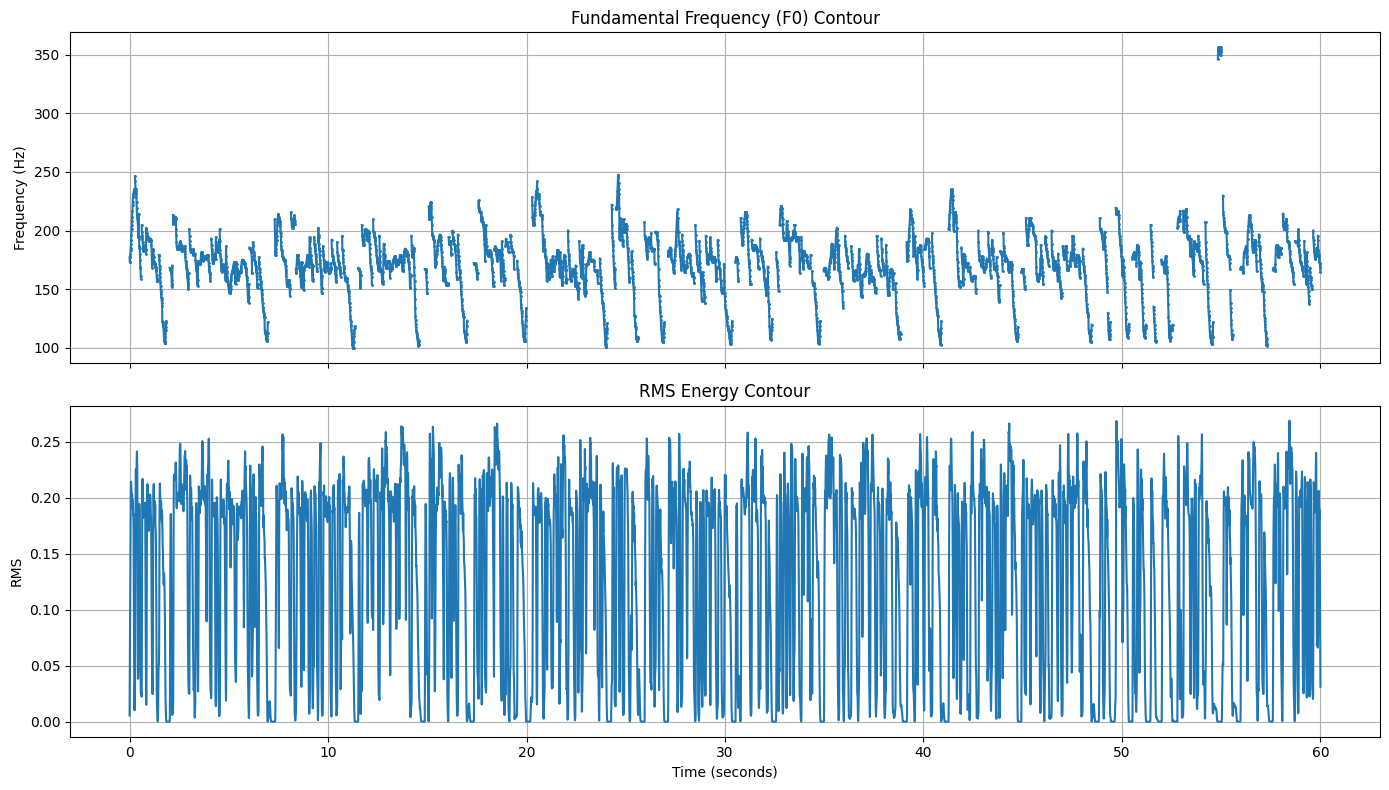

In [14]:
# Visualize pitch and RMS energy together

pitch_times = librosa.times_like(
    f0,
    sr=sr,
    hop_length=HOP_LENGTH
)

rms_times = librosa.times_like(
    rms,
    sr=sr,
    hop_length=HOP_LENGTH
)

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 8),
    sharex=True
)

# Pitch contour
axes[0].plot(
    pitch_times,
    f0,
    marker=".",
    markersize=2
)

axes[0].set_title("Fundamental Frequency (F0) Contour")
axes[0].set_ylabel("Frequency (Hz)")
axes[0].grid()

# RMS contour
axes[1].plot(
    rms_times,
    rms
)

axes[1].set_title("RMS Energy Contour")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("RMS")
axes[1].grid()

plt.tight_layout()
plt.show()